In [1]:
# 1. Install libraries

In [2]:
# 2. Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import time
import warnings
warnings.filterwarnings("ignore")

from scipy.stats import randint, uniform

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate,
    StratifiedKFold
)

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

from sklearn.feature_selection import SelectPercentile, mutual_info_classif

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    RandomForestClassifier,
    GradientBoostingClassifier,
    VotingClassifier
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from sklearn.dummy import DummyClassifier

In [4]:
# Load dataset
df = pd.read_csv("../data/telco_churn.csv")

# Display dataset
print("Dataset shape:", df.shape)
display(df.head())

# Dataset information
df.info()

Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [5]:
# Remove duplicate rows
df = df.drop_duplicates()

# Remove customerID because it is an identifier, not a useful predictive feature
if "customerID" in df.columns:
    df = df.drop(columns=["customerID"])

# Convert TotalCharges to numeric
if "TotalCharges" in df.columns:
    df["TotalCharges"] = pd.to_numeric(
        df["TotalCharges"],
        errors="coerce"
    )

# Check missing values
print("Missing values:")
print(df.isnull().sum())

# Check target distribution
print("\nTarget distribution:")
print(df["Churn"].value_counts())

# Check data types
print("\nData types:")
print(df.dtypes)

Missing values:
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Data types:
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str


In [6]:
# Feature engineering
if "TotalCharges" in df.columns and "tenure" in df.columns:
    df["AvgMonthlySpend"] = (
        df["TotalCharges"] / df["tenure"].replace(0, np.nan)
    )

# Encode target variable
df["Churn"] = df["Churn"].map({
    "Yes": 1,
    "No": 0
})

# Remove rows with missing target values
df = df.dropna(subset=["Churn"])

# Display engineered dataset
display(df.head())

print("Updated dataset shape:", df.shape)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,AvgMonthlySpend
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,...,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0,29.850000
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,...,No,No,No,One year,No,Mailed check,56.95,1889.50,0,55.573529
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,...,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1,54.075000
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,...,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0,40.905556
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1,75.825000


Updated dataset shape: (7043, 21)


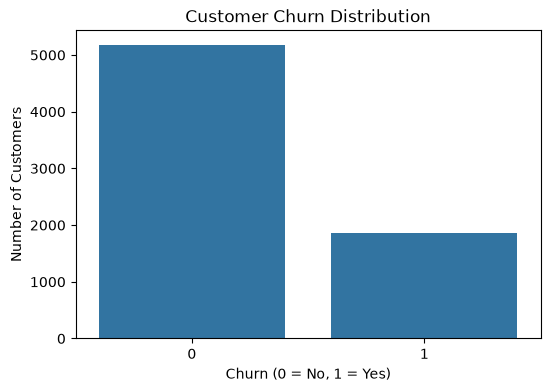

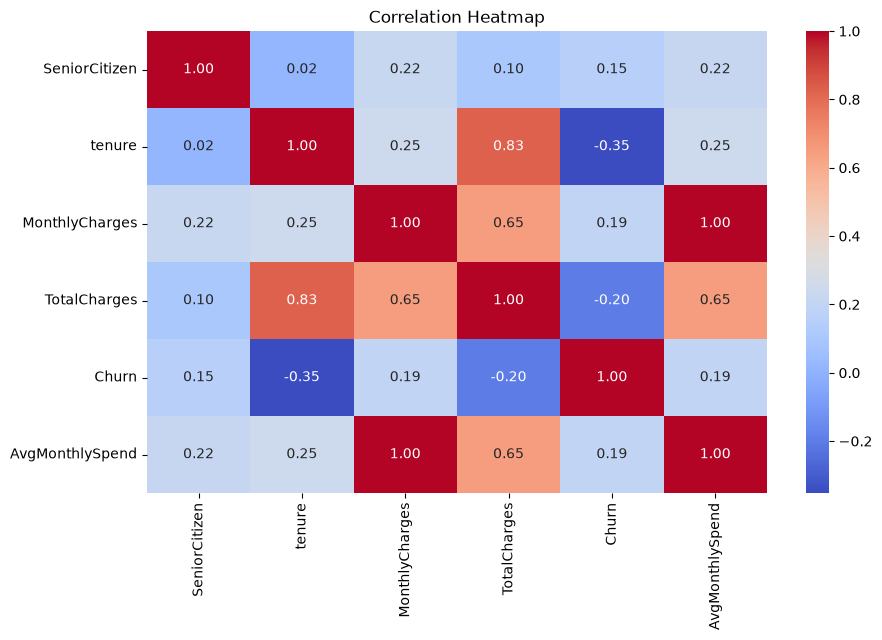

In [7]:
# Target distribution
plt.figure(figsize=(6, 4))

sns.countplot(data=df, x="Churn")

plt.title("Customer Churn Distribution")
plt.xlabel("Churn (0 = No, 1 = Yes)")
plt.ylabel("Number of Customers")
plt.show()

# Correlation heatmap for numerical features
numeric_df = df.select_dtypes(include=np.number)

plt.figure(figsize=(10, 6))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")
plt.show()

In [9]:
# Separate Features and Target
X = df.drop(columns=["Churn"])
y = df["Churn"].astype(int)

# Identify numerical and categorical columns
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

Numerical features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges', 'AvgMonthlySpend']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Training set: (5634, 20)
Testing set: (1409, 20)


In [10]:
# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [13]:
# 9. Baseline Model
# Dummy baseline
dummy_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", DummyClassifier(strategy="most_frequent"))
])

dummy_pipeline.fit(X_train, y_train)

dummy_predictions = dummy_pipeline.predict(X_test)

print("Dummy Baseline Accuracy:",
      accuracy_score(y_test, dummy_predictions))


# Logistic Regression baseline
baseline_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

baseline_pipeline.fit(X_train, y_train)

baseline_predictions = baseline_pipeline.predict(X_test)
baseline_probabilities = baseline_pipeline.predict_proba(X_test)[:, 1]

print("\nLogistic Regression Baseline")
print("Accuracy:", accuracy_score(y_test, baseline_predictions))
print("Precision:", precision_score(y_test, baseline_predictions))
print("Recall:", recall_score(y_test, baseline_predictions))
print("F1:", f1_score(y_test, baseline_predictions))
print("ROC-AUC:", roc_auc_score(y_test, baseline_probabilities))

Dummy Baseline Accuracy: 0.7345635202271115

Logistic Regression Baseline
Accuracy: 0.7388218594748048
Precision: 0.5051724137931034
Recall: 0.7834224598930482
F1: 0.6142557651991615
ROC-AUC: 0.8414942261489576


In [15]:
# 10. Feature Selection

feature_selection_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("feature_selection", SelectPercentile(
        score_func=mutual_info_classif,
        percentile=70
    )),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

feature_selection_pipeline.fit(X_train, y_train)

fs_predictions = feature_selection_pipeline.predict(X_test)

print("Feature Selection Model")
print("Accuracy:", accuracy_score(y_test, fs_predictions))
print("F1:", f1_score(y_test, fs_predictions))

Feature Selection Model
Accuracy: 0.7388218594748048
F1: 0.6174636174636174


In [19]:
# 11. Build complete sklearn Pipeline

# Preprocessing → Feature Selection → Classification

full_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("feature_selection", SelectPercentile(
        score_func=mutual_info_classif,
        percentile=70
    )),

    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

print(full_pipeline)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('scaler',
                                                                   StandardScaler())]),
                                                  ['SeniorCitizen', 'tenure',
                                                   'MonthlyCharges',
                                                   'TotalCharges',
                                                   'AvgMonthlySpend']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                   

In [20]:
# 12. GridSearchCV

param_grid = {
    "feature_selection__percentile": [50, 70, 90, 100],

    "classifier__C": [0.01, 0.1, 1, 10],

    "classifier__solver": ["liblinear", "lbfgs"]
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=full_pipeline,
    param_grid=param_grid,
    scoring="f1",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

start_time = time.time()

grid_search.fit(X_train, y_train)

grid_time = time.time() - start_time

print("Best Parameters:")
print(grid_search.best_params_)

print("\nBest Cross-Validation F1:")
print(grid_search.best_score_)

print("\nGrid Search Time:")
print(grid_time)

Fitting 5 folds for each of 32 candidates, totalling 160 fits
Best Parameters:
{'classifier__C': 10, 'classifier__solver': 'lbfgs', 'feature_selection__percentile': 70}

Best Cross-Validation F1:
0.6311875830934819

Grid Search Time:
17.69146227836609


In [21]:
# 13. RandomizedSearchCV

random_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),

    ("feature_selection", SelectPercentile(
        score_func=mutual_info_classif
    )),

    ("classifier", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

random_param_distributions = {
    "feature_selection__percentile": [50, 70, 90, 100],

    "classifier__n_estimators": randint(100, 500),

    "classifier__max_depth": [None, 5, 10, 15, 20],

    "classifier__min_samples_split": randint(2, 15),

    "classifier__min_samples_leaf": randint(1, 8),

    "classifier__max_features": ["sqrt", "log2"]
}

random_search = RandomizedSearchCV(
    estimator=random_pipeline,
    param_distributions=random_param_distributions,
    n_iter=30,
    scoring="f1",
    cv=cv,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

start_time = time.time()

random_search.fit(X_train, y_train)

random_time = time.time() - start_time

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation F1:")
print(random_search.best_score_)

print("\nRandomized Search Time:")
print(random_time)

Fitting 5 folds for each of 30 candidates, totalling 150 fits
Best Parameters:
{'classifier__max_depth': 20, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 3, 'classifier__min_samples_split': 14, 'classifier__n_estimators': 135, 'feature_selection__percentile': 50}

Best Cross-Validation F1:
0.6346128387976966

Randomized Search Time:
35.844897985458374


In [22]:
# 14. Ensemble Learning

# Logistic Regression
lr_model = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

# Random Forest
rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Gradient Boosting
gb_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

# Voting Classifier
voting_model = VotingClassifier(
    estimators=[
        ("lr", lr_model),
        ("rf", rf_model),
        ("gb", gb_model)
    ],
    voting="soft"
)

ensemble_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("feature_selection", SelectPercentile(
        score_func=mutual_info_classif,
        percentile=70
    )),
    ("classifier", voting_model)
])

start_time = time.time()

ensemble_pipeline.fit(X_train, y_train)

ensemble_time = time.time() - start_time

ensemble_predictions = ensemble_pipeline.predict(X_test)
ensemble_probabilities = ensemble_pipeline.predict_proba(X_test)[:, 1]

print("Ensemble Model")
print("Accuracy:", accuracy_score(y_test, ensemble_predictions))
print("Precision:", precision_score(y_test, ensemble_predictions))
print("Recall:", recall_score(y_test, ensemble_predictions))
print("F1:", f1_score(y_test, ensemble_predictions))
print("ROC-AUC:", roc_auc_score(y_test, ensemble_probabilities))
print("Training Time:", ensemble_time)

Ensemble Model
Accuracy: 0.7750177430801988
Precision: 0.5602536997885835
Recall: 0.7085561497326203
F1: 0.6257378984651711
ROC-AUC: 0.8448448681185255
Training Time: 1.682502031326294


In [23]:
# 15. Cross-Validation

models = {
    "Baseline Logistic Regression": baseline_pipeline,

    "Feature Selection Logistic Regression":
        feature_selection_pipeline,

    "GridSearchCV Best Model":
        grid_search.best_estimator_,

    "RandomizedSearchCV Best Model":
        random_search.best_estimator_,

    "Ensemble Model":
        ensemble_pipeline
}

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc"
}

cv_results = []

for name, model in models.items():

    print(f"\nEvaluating {name}...")

    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        by="F1",
        ascending=False
    )
)


Evaluating Baseline Logistic Regression...

Evaluating Feature Selection Logistic Regression...

Evaluating GridSearchCV Best Model...

Evaluating RandomizedSearchCV Best Model...

Evaluating Ensemble Model...


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
4,Ensemble Model,0.785589,0.578329,0.707023,0.636159,0.848910
3,RandomizedSearchCV Best Model,0.766244,0.542945,0.757860,0.632506,0.843486
0,Baseline Logistic Regression,0.750268,0.519161,0.800669,0.629737,0.845506
1,Feature Selection Logistic Regression,0.747784,0.516163,0.798662,0.626849,0.845092
2,GridSearchCV Best Model,0.746186,0.514214,0.796656,0.624813,0.843892


In [24]:
# 16. Final Model Selection

# Select model with highest cross-validation F1
best_model_name = cv_results_df.loc[
    cv_results_df["F1"].idxmax(),
    "Model"
]

final_model = models[best_model_name]

print("Selected Final Model:", best_model_name)

# Fit selected model on the full training dataset
final_model.fit(X_train, y_train)

# Test set predictions
final_predictions = final_model.predict(X_test)

final_probabilities = final_model.predict_proba(X_test)[:, 1]

print("\nFinal Model Test Results")

print("Accuracy:",
      accuracy_score(y_test, final_predictions))

print("Precision:",
      precision_score(y_test, final_predictions))

print("Recall:",
      recall_score(y_test, final_predictions))

print("F1-score:",
      f1_score(y_test, final_predictions))

print("ROC-AUC:",
      roc_auc_score(y_test, final_probabilities))

print("\nClassification Report:")
print(classification_report(y_test, final_predictions))

Selected Final Model: Ensemble Model

Final Model Test Results
Accuracy: 0.7693399574166075
Precision: 0.5520169851380042
Recall: 0.6951871657754011
F1-score: 0.6153846153846154
ROC-AUC: 0.842240822547728

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.80      0.84      1035
           1       0.55      0.70      0.62       374

    accuracy                           0.77      1409
   macro avg       0.72      0.75      0.73      1409
weighted avg       0.79      0.77      0.78      1409



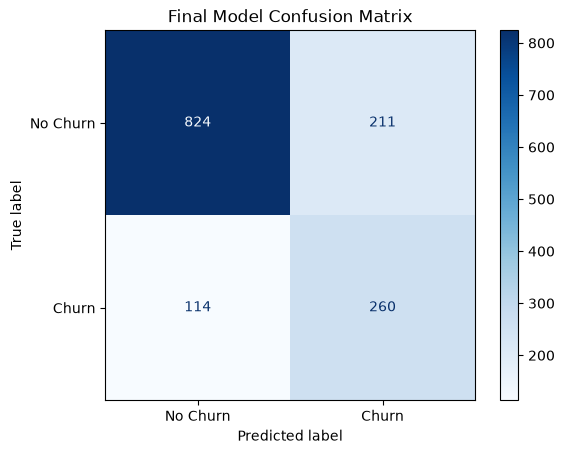

In [25]:
# 17. Confusion Matrix

cm = confusion_matrix(y_test, final_predictions)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

disp.plot(cmap="Blues")

plt.title("Final Model Confusion Matrix")
plt.show()

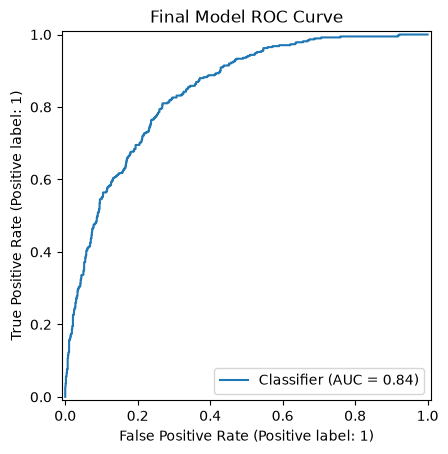

In [26]:
# 18. ROC Curve

RocCurveDisplay.from_predictions(
    y_test,
    final_probabilities
)

plt.title("Final Model ROC Curve")
plt.show()

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
4,Ensemble Model,0.785589,0.578329,0.707023,0.636159,0.848910
3,RandomizedSearchCV Best Model,0.766244,0.542945,0.757860,0.632506,0.843486
0,Baseline Logistic Regression,0.750268,0.519161,0.800669,0.629737,0.845506
1,Feature Selection Logistic Regression,0.747784,0.516163,0.798662,0.626849,0.845092
2,GridSearchCV Best Model,0.746186,0.514214,0.796656,0.624813,0.843892


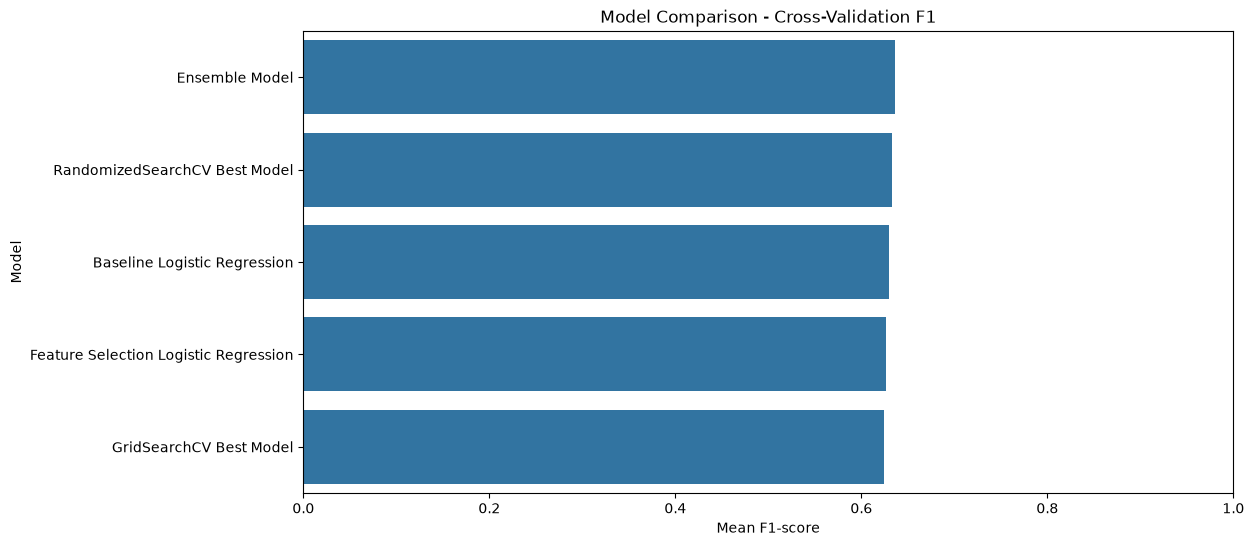

In [27]:
# 19. Compare All Models

comparison = cv_results_df.sort_values(
    by="F1",
    ascending=False
)

display(comparison)

# Visualize F1 scores
plt.figure(figsize=(12, 6))

sns.barplot(
    data=comparison,
    x="F1",
    y="Model"
)

plt.title("Model Comparison - Cross-Validation F1")
plt.xlabel("Mean F1-score")
plt.ylabel("Model")
plt.xlim(0, 1)

plt.show()

In [28]:
# 20. Save Final Model

import joblib

joblib.dump(
    final_model,
    "problem12_final_model.pkl"
)

print("Final model saved successfully.")

Final model saved successfully.


In [29]:
# 21. Make Predictions on New Data

# Example: predict on a few customers from the test set
sample_customers = X_test.head(5)

sample_predictions = final_model.predict(sample_customers)

sample_probabilities = final_model.predict_proba(
    sample_customers
)[:, 1]

prediction_results = pd.DataFrame({
    "Actual": y_test.head(5).values,
    "Predicted": sample_predictions,
    "Churn Probability": sample_probabilities
})

display(prediction_results)

,Actual,Predicted,Churn Probability
0,0,0,0.049361
1,0,1,0.802069
2,0,0,0.155035
3,0,1,0.539545
4,0,0,0.041327


In [30]:
# 22. Final Summary

print("=" * 50)
print("PROBLEM 12 - ADVANCED ML CHALLENGE SUMMARY")
print("=" * 50)

print("Dataset Size:", df.shape)

print("\nGridSearchCV")
print("Best F1:", grid_search.best_score_)
print("Search Time:", round(grid_time, 2), "seconds")

print("\nRandomizedSearchCV")
print("Best F1:", random_search.best_score_)
print("Search Time:", round(random_time, 2), "seconds")

print("\nFinal Selected Model:", best_model_name)

print("\nFinal Test Metrics")
print("Accuracy:", round(accuracy_score(y_test, final_predictions), 4))
print("Precision:", round(precision_score(y_test, final_predictions), 4))
print("Recall:", round(recall_score(y_test, final_predictions), 4))
print("F1:", round(f1_score(y_test, final_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, final_probabilities), 4))

print("=" * 50)

PROBLEM 12 - ADVANCED ML CHALLENGE SUMMARY
Dataset Size: (7043, 21)

GridSearchCV
Best F1: 0.6311875830934819
Search Time: 17.69 seconds

RandomizedSearchCV
Best F1: 0.6346128387976966
Search Time: 35.84 seconds

Final Selected Model: Ensemble Model

Final Test Metrics
Accuracy: 0.7693
Precision: 0.552
Recall: 0.6952
F1: 0.6154
ROC-AUC: 0.8422
